## LAB | Prompt Engineering Lab


### Part 1: Creating Initial Prompts

In [18]:
import os
from openai import OpenAI
import json
from collections import Counter
import time
from dotenv import load_dotenv
import pandas as pd

In [2]:
load_dotenv()
client = OpenAI(api_key=os.environ.get("OPENAI_API_KEY"))
MODEL = "gpt-4o-mini"

#### Helper Function

In [3]:
def call_openai(prompt, system_message="You are a helpful assistant.", temperature=0.7, max_tokens=None, seed=None):
    """Helper function to call OpenAI API with specified parameters"""
    try:
        params = {
            "model": MODEL,
            "messages": [
                {"role": "system", "content": system_message},
                {"role": "user", "content": prompt}
            ],
            "temperature": temperature
        }
        
        if max_tokens:
            params["max_tokens"] = max_tokens
        if seed is not None:
            params["seed"] = seed
            
        response = client.chat.completions.create(**params)
        return response.choices[0].message.content
    except Exception as e:
        return f"Error: {str(e)}"

def display_response(title, response, params=None):
    """Display a response with formatting"""
    print(f"\n{'='*60}")
    print(f"📝 {title}")
    if params:
        print(f"Parameters: {params}")
    print(f"{'='*60}")
    print(response)
    print(f"{'='*60}\n")

def count_tokens_approx(text):
    """Approximate token count (roughly 4 characters per token)"""
    return len(text) // 4

print("✅ Helper functions loaded!")

✅ Helper functions loaded!


#### Task 1: Sentiment Analysis

In [4]:
sentiment_prompt_v1 = """
Classify this customer message: "I love this product! It's exactly what I needed."
"""
 
result1 = call_openai(sentiment_prompt_v1)
print("Sentiment Analysis Result:")
print(result1)

Sentiment Analysis Result:
The customer message can be classified as **Positive Feedback**.


#### Task 2: Product Description Generation

In [5]:
product_prompt_v1 = """
Create a product description for a wireless mouse that costs $29.99.
"""
 
result2 = call_openai(product_prompt_v1)
print("Product Description Result:")
print(result2)

Product Description Result:
**Product Description: Wireless Comfort Mouse**

Elevate your computing experience with the Wireless Comfort Mouse, designed for seamless navigation and ultimate convenience. Priced at just $29.99, this sleek and stylish mouse combines functionality with a modern aesthetic, making it the perfect accessory for home, office, or on-the-go use.

**Key Features:**

- **Wireless Freedom:** Enjoy the convenience of a wireless connection with a reliable range of up to 33 feet. Say goodbye to tangled cords and embrace the freedom to move around your workspace effortlessly.

- **Ergonomic Design:** Crafted with comfort in mind, the Wireless Comfort Mouse features a carefully contoured shape that fits snugly in your hand, reducing strain during extended use. Whether you're working on a project or browsing the web, you'll appreciate the comfort it provides.

- **Precision Tracking:** Equipped with advanced optical sensor technology, this mouse offers smooth and precise 

#### Task 3: Data Extraction 

In [6]:
# Initial simple prompt for data extraction
extraction_prompt_v1 = """
Extract information from this customer feedback: "I ordered item #12345 on March 15th. The delivery was fast but the packaging was damaged."
"""
 
# Test it once
result3 = call_openai(extraction_prompt_v1)
print("Data Extraction Result:")
print(result3)

Data Extraction Result:
Here is the extracted information from the customer feedback:

- **Order Number:** #12345
- **Order Date:** March 15th
- **Delivery Speed:** Fast
- **Packaging Condition:** Damaged


### Part 2: Diagnosing Failures - Systematic Testing 

####  Run Prompts 5, 10, 15 Times

In [67]:
prompts = {
    "sentiment": sentiment_prompt_v1,
    "product": product_prompt_v1,
    "extraction": extraction_prompt_v1,
}

def iterations(num_runs, prompts,temperature=0.7, verbose=True):
    
    print(f"Running the same prompt {num_runs} times with temperature={temperature}")

    all_responses = {}

    for name, prompt in prompts.items():
        print("=" * 80)
        print(f"PROMPT: {name}")
        print(f"{prompt}\n")
        
        responses=[]
        
        for i in range(num_runs):
            response = call_openai(prompt, temperature=temperature)
            responses.append(response)
            print(f"\n🔄 Run #{i+1}:")
            print(response)
            print("-"*80)
            time.sleep(0.5)  # Small delay to avoid rate limiting
        
        all_responses[name]=responses 
        
    return all_responses
            


results_by_n = {}
for n in [5, 10, 15]:
    results_by_n[n] = iterations(n, prompts,verbose=False)




Running the same prompt 5 times with temperature=0.7
PROMPT: sentiment

Classify this customer message: "I love this product! It's exactly what I needed."



🔄 Run #1:
This customer message can be classified as "Positive Feedback" or "Satisfaction."
--------------------------------------------------------------------------------

🔄 Run #2:
The customer message can be classified as **positive feedback** or **customer satisfaction**.
--------------------------------------------------------------------------------

🔄 Run #3:
This customer message can be classified as positive feedback or a customer satisfaction message.
--------------------------------------------------------------------------------

🔄 Run #4:
The customer message can be classified as **Positive Feedback** or **Customer Praise**.
--------------------------------------------------------------------------------

🔄 Run #5:
This customer message can be classified as positive feedback or positive sentiment.
-------------------

In [19]:
import statistics
from difflib import SequenceMatcher

def avg_similarity(responses):
    if len(responses) < 2:
        return 1.0
    sims = [SequenceMatcher(None, a, b).ratio()
            for i, a in enumerate(responses) for b in responses[i + 1:]]
    return sum(sims) / len(sims)

def variation_by_runs(results_by_n):
    rows = []
    for n, all_responses in results_by_n.items():
        for name, responses in all_responses.items():
            responses = [r for r in responses if r]
            words = [len(r.split()) for r in responses]
            rows.append({
                "prompt": name,
                "runs": n,
                "unique": len(set(responses)),
                "unique_%": round(100 * len(set(responses)) / len(responses)),
                "avg_similarity": round(avg_similarity(responses), 2),
                "avg_words": round(statistics.mean(words), 1),
                "words_std": round(statistics.pstdev(words), 1),
            })
    return pd.DataFrame(rows).sort_values(["prompt", "runs"]).reset_index(drop=True)

df = variation_by_runs(results_by_n)
df

,prompt,runs,unique,unique_%,avg_similarity,avg_words,words_std
0,extraction,5,3,60,0.94,26.2,0.4
1,extraction,10,7,70,0.88,24.9,2.7
2,extraction,15,11,73,0.93,25.4,1.5
3,product,5,5,100,0.21,301.0,16.3
4,product,10,10,100,0.16,297.8,20.4
5,product,15,15,100,0.16,295.4,21.8
6,sentiment,5,3,60,0.87,10.2,1.6
7,sentiment,10,9,90,0.83,11.7,1.6
8,sentiment,15,9,60,0.82,14.2,4.7


Sentiment: consistent, with some drift

- Similarity is 0.82-0.87, and average length grows (10.2 → 11.7 → 14.2) with words_std rising to 4.7 at 15 runs. Some responses are probably adding an explanation beyond the label.

- With this v1 prompt, the model sometimes labels only, sometimes explains.

- The unique % jump between 10 and 15 runs (90 → 60) is partly a sampling artifact; unique counts are noisy at these sample sizes.

Product: the most variable, and the only one that’s really “creative”

- avg_similarity of 0.16-0.21 means any two responses share very little text. unique_% is 100 at every run count, so no two descriptions were ever identical.

- Average length is about 300 words with a standard deviation of 16-22, so lengths swing by roughly ±20 words. That’s what you’d expect from the pruduct_v1 prompt, which has no length or format constraints.

- Stable across 5, 10 and 15 runs (0.21 → 0.16 → 0.16), so 5 runs was already enough to see this.

Extraction: low variation in content, some in wording

- Similarity of 0.88-0.94 and about 25 words per response: the outputs are short and close to each other. The model is extracting the same facts and phrasing them slightly differently.

- Unique % rises with run count (60 → 70 → 73), but similarity stays high, so the differences are small wording changes rather than different content.

- The 10-run row looks the most variable (0.88, std 2.7). That is probably one or two outlier responses, not a trend.



### Part 3: Iteration 1 - Rewriting Simple Prompts

In [31]:

def refine_prompt_loop(initial_prompt, refinement_template, iterations=3,
                       temperature=0.7, verbose=True):
   
    current_prompt = initial_prompt
    history = []

    for i in range(iterations):
        output = call_openai(current_prompt, temperature=temperature)
        history.append({"iteration": i + 1, "prompt": current_prompt, "output": output})

        if i < iterations - 1:
            refinement_prompt = refinement_template.format(
                current_prompt=current_prompt, output=output
            )
            refined = call_openai(refinement_prompt, temperature=temperature)

            if not refined or not refined.strip():
                print("Refinement returned empty. Stopping early.")
                break

            current_prompt = refined.strip()
            if verbose:
                print(f" Refined prompt:\n{current_prompt}")
                print("-" * 80)
            time.sleep(0.5)

    return history

def history_table(history):
    return pd.DataFrame([{
        "iteration": h["iteration"],
        "prompt_words": len(h["prompt"].split()),
        "output_words": len(h["output"].split()),
        "output_preview": h["output"][:80].replace("\n", " "),
    } for h in history])

##### Improve Sentiment Analysis Prompt

In [27]:
sentiment_refinement = """I used this prompt: "{current_prompt}"
And got this output: "{output}"
The output is good but could be better. Improve the prompt to generate:
- Clearer instructions
- Explicit output format requirement
- Constraints (single word response)
Return ONLY the improved prompt.
"""

sentiment_history  = refine_prompt_loop(sentiment_prompt_v1, sentiment_refinement)


 Refined prompt:
Classify the following customer message and provide a single word response: "I love this product! It's exactly what I needed." Your output should indicate the sentiment of the message, such as Positive, Negative, or Neutral. Please ensure your response is concise and in the specified format.
--------------------------------------------------------------------------------
 Refined prompt:
"Classify the following customer message based on its sentiment. Provide a single word response indicating the sentiment: Positive, Negative, or Neutral. Ensure your response is clear, concise, and follows the format: 'Sentiment: [Your Response]'. Please restrict your answer to only one word."
--------------------------------------------------------------------------------


In [32]:
history_table(sentiment_history)

,iteration,prompt_words,output_words,output_preview
0,1,13,9,The customer message can be classified as **Po...
1,2,46,1,Positive
2,3,42,2,Sentiment: Neutral


#####  Improve Product Description Prompt

In [45]:
product_refinement = """I used this prompt: "{current_prompt}"
And got this output: "{output}"
The output is good but could be better. Improve the prompt to generate:
- A fixed structure: headline, opening hook, 3 bullets, closing line
- Total length of 70-100 words
- A friendly, confident, professional style with no emojis
- No invented specs or claims
Keep the product details in the prompt.

Return ONLY the improved prompt."""


product_history= refine_prompt_loop(product_prompt_v1,product_refinement)

 Refined prompt:
Create a product description for a wireless mouse that costs $29.99, following this fixed structure: 

1. Headline
2. Opening hook
3. Three bullet points highlighting key features
4. Closing line

Ensure the total length is between 70-100 words. The style should be friendly, confident, and professional, without using emojis. Do not include invented specifications or claims, but retain the following product details: 

- Wireless convenience with a 2.4GHz USB receiver
- Ergonomic design for comfort during extended use
- Precision tracking on various surfaces
- Customizable buttons for productivity
- Long battery life
- Stylish aesthetics in multiple colors
- Compatibility with Windows, macOS, and Linux

Include what is included in the package.
--------------------------------------------------------------------------------
 Refined prompt:
Create a product description for a wireless mouse priced at $29.99, following this fixed structure:

1. Headline
2. Opening hook
3. T

In [46]:
history_table(product_history)

,iteration,prompt_words,output_words,output_preview
0,1,11,310,**Product Name: SwiftConnect Wireless Mouse** ...
1,2,113,94,**Effortless Control at Your Fingertips** Dis...
2,3,116,94,**Elevate Your Workspace with Our Wireless Mou...


In [51]:
print(product_history[2]["output"])

**Elevate Your Workspace with Our Wireless Mouse**

Experience the freedom of wireless convenience with our sleek and stylish wireless mouse, priced at just $29.99. Perfect for both work and play, it combines functionality with modern aesthetics.

- Enjoy seamless connectivity with a 2.4GHz USB receiver, ensuring a lag-free experience.
- Ergonomic design provides comfort for hours of use, making it ideal for professionals and gamers alike.
- Precision tracking on various surfaces and customizable buttons enhance your productivity.

Included in the package is the wireless mouse and the USB receiver. Upgrade your setup today!


##### Improve Data Extraction Prompt

In [29]:
extraction_refinement = """I used this prompt: "{current_prompt}"
And got this output: "{output}"
The output is good but could be better. Improve the prompt to generate:
- Output as JSON with keys: item_number, order_date, positive_points, negative_points
- Only facts stated in the text, with "Not provided" for anything missing

Keep the original feedback text in the prompt.

Return ONLY the improved prompt."""


extraction_history = refine_prompt_loop(extraction_prompt_v1, extraction_refinement)

 Refined prompt:
Extract information from this customer feedback: "I ordered item #12345 on March 15th. The delivery was fast but the packaging was damaged." 

Please provide the extracted information in JSON format with the following keys: 
- item_number 
- order_date 
- positive_points 
- negative_points 

Ensure that only factual statements from the text are included, and use "Not provided" for any missing information.
--------------------------------------------------------------------------------
 Refined prompt:
Extract information from this customer feedback: "I ordered item #12345 on March 15th. The delivery was fast but the packaging was damaged." 

Please provide the extracted information in JSON format with the following keys: 
- item_number 
- order_date 
- positive_points 
- negative_points 

Ensure that only factual statements from the text are included, and use "Not provided" for any missing information. Please format the output correctly as JSON.
-----------------------

In [34]:
history_table(extraction_history)

,iteration,prompt_words,output_words,output_preview
0,1,22,26,Here is the extracted information from the cus...
1,2,60,27,Here is the extracted information in JSON form...
2,3,67,19,"```json { ""item_number"": ""12345"", ""order_d..."


### Part 4: Iteration 2 - Adding Structure & Constraints

#### Examples to Sentiment Analysis

In [34]:
sentiment_prompt_few_shot = """Classify the sentiment of each customer message as Positive, Negative, or Neutral.
Respond with only the label.

Message: "The battery died after two days. Total waste of money."
Sentiment: Negative

Message: "It arrived on time and works as described."
Sentiment: Neutral

Message: "Amazing quality, I'd buy it again in a heartbeat!"
Sentiment: Positive

Message: "Customer support never answered my emails and the item is broken."
Sentiment: Negative

Message: "I love this product! It's exactly what I needed."
Sentiment:"""

temperature = 0.7
num_runs = 15



print(f"Running the same prompt {num_runs} times with temperature={temperature}")
print("="*80)

responses = []
for i in range(num_runs):
    response = call_openai(sentiment_prompt_few_shot, temperature=temperature)
    responses.append(response)
    print(f"\n🔄 Run #{i+1}:")
    print(response)
    time.sleep(0.5)  # Small delay to avoid rate limiting
 
 

Running the same prompt 15 times with temperature=0.7

🔄 Run #1:
Positive

🔄 Run #2:
Positive

🔄 Run #3:
Positive

🔄 Run #4:
Positive

🔄 Run #5:
Positive

🔄 Run #6:
Positive

🔄 Run #7:
Positive

🔄 Run #8:
Positive

🔄 Run #9:
Positive

🔄 Run #10:
Positive

🔄 Run #11:
Positive

🔄 Run #12:
Positive

🔄 Run #13:
Positive

🔄 Run #14:
Positive

🔄 Run #15:
Positive


#### Chain-of-Thought to Data Extraction

In [54]:
extraction_prompt_cot="""
Extract information from this customer feedback: "I ordered item #12345 on March 15th. The delivery was fast but the packaging was damaged."
Think through this step by step before answering. Show your reasoning for each step.
"""

response = call_openai(extraction_prompt_cot, temperature=0)
display_response("Chain-of-Thought Prompting", response)


📝 Chain-of-Thought Prompting
To extract information from the customer feedback, I will break down the statement into key components and analyze each part step by step.

1. **Identify the Order Information**:
   - The customer mentions "I ordered item #12345". This indicates the specific item that was ordered. 
   - The order number is **#12345**.

2. **Determine the Order Date**:
   - The customer states "on March 15th". This provides the date when the order was placed.
   - The order date is **March 15th**.

3. **Evaluate the Delivery Experience**:
   - The customer comments, "The delivery was fast". This indicates a positive experience regarding the speed of delivery.
   - The delivery experience can be summarized as **fast delivery**.

4. **Assess the Packaging Condition**:
   - The customer notes, "but the packaging was damaged". This indicates a negative aspect of the order related to the condition of the packaging upon arrival.
   - The packaging condition is described as **dama

In [ ]:
num_runs=10

responses = []
for i in range(num_runs):
    response = call_openai(extraction_prompt_cot , temperature=temperature)
    responses.append(response)
    print(f"\n🔄 Run #{i+1}:")
    print(response)
    time.sleep(0.5)  # Small delay to avoid rate limiting
 


🔄 Run #1:
To extract information from the customer feedback provided, we can break it down into several key components. Here's a step-by-step analysis:

1. **Identify the Order Details**: The feedback mentions an order with a specific item number. 
   - **Extracted Information**: Item number is #12345.

2. **Determine the Order Date**: The customer specifies when they placed the order.
   - **Extracted Information**: Order date is March 15th.

3. **Assess Delivery Speed**: The feedback includes a comment about the delivery speed.
   - **Extracted Information**: Delivery was described as "fast."

4. **Evaluate Packaging Condition**: The customer provides feedback on the condition of the packaging upon delivery.
   - **Extracted Information**: The packaging was "damaged."

Now, let's compile this information into a clear summary:

- **Order Number**: #12345
- **Order Date**: March 15th
- **Delivery Speed**: Fast
- **Packaging Condition**: Damaged

This breakdown allows us to clearly und

#### Few-Shot Examples and Structure to Product Description

In [37]:
product_prompt_few_shot = """
You are an e-commerce copywriter. Write a product description for the product below.

RULES:
- Follow the exact format shown in the examples.
- Total length: 70-100 words. Each bullet: max 20 words.
- Tone: friendly, confident, and professional. No emojis.
- Use only the details provided. Do not invent specs or claims.

---
Product: Stainless Steel Water Bottle, $24.99, keeps drinks cold 24 hours, 750ml, leak-proof lid
Description:
Headline: Stay Cold All Day Long
Your drink deserves to stay as fresh as your day is busy.
- Keep drinks cold for 24 hours with double-wall stainless steel insulation.
- Carry plenty of water with a 750ml capacity built for long days.
- Toss it in your bag worry-free thanks to the leak-proof lid.
Grab yours today for just $24.99.

---
Product: Bluetooth Desk Lamp, $39.99, 3 brightness levels, touch controls, USB charging port
Description:
Headline: Light Your Work, Your Way
Great focus starts with lighting that adapts to you.
- Adjust the mood with 3 brightness levels at a simple touch.
- Control everything easily with responsive touch controls.
- Charge your phone while you work using the built-in USB port.
Bring brighter, smarter lighting to your desk for $39.99.

---
Product: Wireless Mouse, $29.99
Description:
"""

response = call_openai(product_prompt_few_shot, temperature=0)
display_response("Chain-of-Thought Prompting", response)



📝 Chain-of-Thought Prompting
Headline: Navigate with Ease  
Experience seamless control and comfort with every click.  
- Enjoy wireless freedom with a reliable connection for smooth navigation.  
- Ergonomic design fits perfectly in your hand for all-day comfort.  
- Long-lasting battery ensures you stay productive without interruptions.  
Upgrade your workspace with this essential accessory for just $29.99.



In [38]:
num_runs=15

responses = []
for i in range(num_runs):
    response = call_openai(product_prompt_few_shot , temperature=temperature)
    responses.append(response)
    print(f"\n🔄 Run #{i+1}:")
    print(response)
    time.sleep(0.5)  # Small delay to avoid rate limiting


🔄 Run #1:
Headline: Navigate with Ease and Style  
Experience effortless control with our sleek wireless mouse.  
- Enjoy freedom of movement without tangled cords or restrictions.  
- Ergonomic design provides comfort for long hours of use.  
- Long-lasting battery ensures you stay productive all day.  
Upgrade your workspace with this essential accessory for just $29.99.

🔄 Run #2:
Headline: Navigate with Ease  
Experience seamless control with a mouse designed for comfort and efficiency.  
- Enjoy wireless freedom with a reliable connection.  
- Ergonomic design fits perfectly in your hand for long use.  
- Compact and portable, perfect for on-the-go professionals.  
Elevate your workspace with this must-have accessory for just $29.99.

🔄 Run #3:
Headline: Navigate with Ease  
Experience seamless control and comfort with every click.  
- Enjoy wireless freedom with a reliable connection for smooth navigation.  
- Ergonomic design fits comfortably in your hand for extended use.  
- 

- **Sentiment Analysis:** Adding few-shot examples in v3 made the output follow a known set of categories (Positive, Negative, Neutral), which removed the extra explanatory text seen in v1 and reduced variation between runs.

- **Extraction Analysis:** Adding chain-of-thought in v3 made the output longer than v1, because the model now shows its reasoning steps before the extracted data. The trade-off is more transparency and fewer unsupported claims, at the cost of length.

- **Product Analysis:** v1 had no length limit or structure, so outputs averaged about 300 words and varied widely in format. v3 added a fixed structure, a 70-100 word limit and style rules, which made the descriptions shorter, more consistent and easier to scan.

### Part 5: Tuning for Different Tasks

#### Task Variations

In [52]:
sentiment_prompt_v4= """Classify the following customer message and provide a single word response:"I bought this product after reading very good reviews and it was fine.." 
Your output should indicate the sentiment of the message, such as Positive, Negative, or Neutral. Please ensure your response is concise and in the specified format.
"""

Sentiment_v4=call_openai(sentiment_prompt_v4)
print(Sentiment_v4)

Neutral


In [53]:
product_prompt_v4= """
You are an e-commerce copywriter. Write a product description for the product below.

RULES:
- Follow the exact format shown in the examples.
- Total length: 70-100 words. Each bullet: max 20 words.
- Tone: friendly, confident, and professional. No emojis.
- Use only the details provided. Do not invent specs or claims.

---
Product: Stainless Steel Water Bottle, $24.99, keeps drinks cold 24 hours, 750ml, leak-proof lid
Description:
Headline: Stay Cold All Day Long
Your drink deserves to stay as fresh as your day is busy.
- Keep drinks cold for 24 hours with double-wall stainless steel insulation.
- Carry plenty of water with a 750ml capacity built for long days.
- Toss it in your bag worry-free thanks to the leak-proof lid.
Grab yours today for just $24.99.

---
Product: Bluetooth Desk Lamp, $39.99, 3 brightness levels, touch controls, USB charging port
Description:
Headline: Light Your Work, Your Way
Great focus starts with lighting that adapts to you.
- Adjust the mood with 3 brightness levels at a simple touch.
- Control everything easily with responsive touch controls.
- Charge your phone while you work using the built-in USB port.
Bring brighter, smarter lighting to your desk for $39.99.

---
Product: Gaming Laptop, $1.298.999
Description:
"""


product_v4=call_openai(product_prompt_v4)
print(product_v4)

Headline: Level Up Your Gaming Experience  
Unleash your potential with a laptop designed for serious gamers.  
- Immerse yourself in stunning graphics that enhance gameplay.  
- Experience lightning-fast performance with cutting-edge technology.  
- Stay cool under pressure with advanced cooling systems.  
Elevate your gaming setup today for just $1,298.99.


In [61]:
extraction_prompt_v4="""
Extract information from this customer feedback: "I ordered item #9876 on Otober 1st. I didnt' receive my delivery till now." 

Please provide the extracted information in JSON format with the following keys: 
- item_number 
- order_date 
- positive_points 
- negative_points 

Ensure that only factual statements from the text are included, and use "Not provided" for any missing information. Please format the output correctly as JSON.
"""

data_v4=call_openai(extraction_prompt_v4)
print(data_v4)


```json
{
  "item_number": "9876",
  "order_date": "October 1st",
  "positive_points": "Not provided",
  "negative_points": "Did not receive delivery till now"
}
```


####  Final Evaluation and Comparison

In [74]:
prompts_v4 = {
    "sentiment": sentiment_prompt_v4,
    "product": product_prompt_v4,
    "extraction": extraction_prompt_v4,
}


results_v4 = iterations(15,prompts_v4,verbose=False)


Running the same prompt 15 times with temperature=0.7
PROMPT: sentiment
Classify the following customer message and provide a single word response:"I bought this product after reading very good reviews and it was fine.." 
Your output should indicate the sentiment of the message, such as Positive, Negative, or Neutral. Please ensure your response is concise and in the specified format.



🔄 Run #1:
Neutral
--------------------------------------------------------------------------------

🔄 Run #2:
Positive
--------------------------------------------------------------------------------

🔄 Run #3:
Positive
--------------------------------------------------------------------------------

🔄 Run #4:
Neutral
--------------------------------------------------------------------------------

🔄 Run #5:
Neutral
--------------------------------------------------------------------------------

🔄 Run #6:
Neutral
--------------------------------------------------------------------------------

🔄 Run #

In [75]:
versions = {
    "v1": results_by_n[15],   # {"sentiment": [...], "product": [...], "extraction": [...]}
    "v4": results_v4,
    # "v3": results_v3,       # add it if you kept it
}

1. Metrics, including whether each output followed the required format

In [76]:
# --- format checks: return True if a response follows the target format ---
def ok_sentiment(r):
    return r.strip().strip('."\'*').lower() in {"positive", "negative", "neutral"}

def ok_product(r):
    words = len(r.split())
    bullets = sum(1 for line in r.splitlines() if line.strip().startswith("-"))
    return 70 <= words <= 100 and "Headline:" in r and bullets == 3

def ok_extraction(r):
    text = r.split("FINAL ANSWER:")[-1]              # ignores CoT reasoning if present
    text = text.strip().strip("`").removeprefix("json").strip()
    try:
        json.loads(text)
        return True
    except Exception:
        return False

format_checks = {"sentiment": ok_sentiment, "product": ok_product, "extraction": ok_extraction}

def compare_versions(versions):
    rows = []
    for version, all_responses in versions.items():
        for prompt, responses in all_responses.items():
            responses = [r for r in responses if r]
            words = [len(r.split()) for r in responses]
            rows.append({
                "prompt": prompt,
                "version": version,
                "runs": len(responses),
                "unique_%": round(100 * len(set(responses)) / len(responses)),
                "avg_similarity": round(avg_similarity(responses), 2),
                "avg_words": round(statistics.mean(words), 1),
                "words_std": round(statistics.pstdev(words), 1),
                "format_ok_%": round(100 * sum(format_checks[prompt](r) for r in responses) / len(responses)),
            })
    return pd.DataFrame(rows).sort_values(["prompt", "version"]).reset_index(drop=True)

comparison = compare_versions(versions)
comparison

,prompt,version,runs,unique_%,avg_similarity,avg_words,words_std,format_ok_%
0,extraction,v1,15,60,0.92,25.9,0.6,0
1,extraction,v4,15,13,0.99,17.4,0.8,100
2,product,v1,15,100,0.18,290.4,19.3,0
3,product,v4,15,100,0.25,51.0,3.4,0
4,sentiment,v1,15,73,0.85,11.3,1.3,0
5,sentiment,v4,15,13,0.70,1.0,0.0,100


2. Improvement table (first version → last version)

In [77]:
def delta_table(df, base="v1", new="v4"):
    metrics = ["unique_%", "avg_similarity", "avg_words", "words_std", "format_ok_%"]
    b = df[df.version == base].set_index("prompt")[metrics]
    n = df[df.version == new].set_index("prompt")[metrics]
    out = n - b
    out.columns = [f"Δ {c}" for c in metrics]
    return out.round(2)

delta_table(comparison)

,Δ unique_%,Δ avg_similarity,Δ avg_words,Δ words_std,Δ format_ok_%
prompt,,,,,
extraction,-47,0.07,-8.5,0.2,100
product,0,0.07,-239.4,-15.9,0
sentiment,-60,-0.15,-10.3,-1.3,100


3. Charts

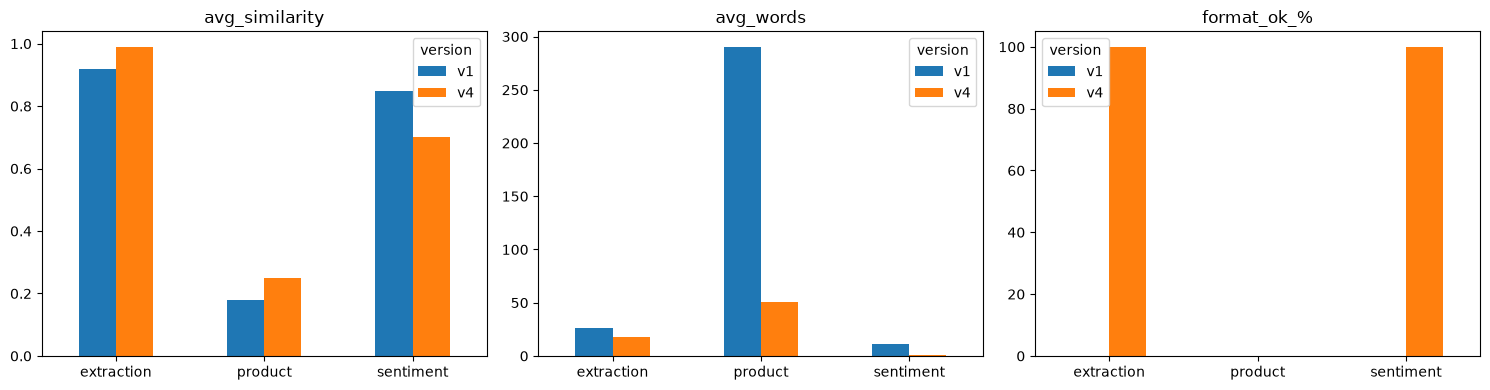

In [78]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["avg_similarity", "avg_words", "format_ok_%"]):
    comparison.pivot(index="prompt", columns="version", values=metric).plot.bar(ax=ax, rot=0)
    ax.set_title(metric)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("comparison_chart.png", dpi=150)
plt.show()